# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

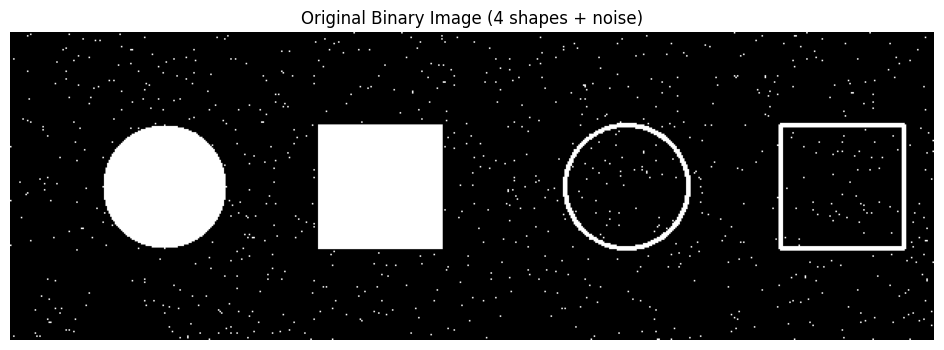

In [4]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [5]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



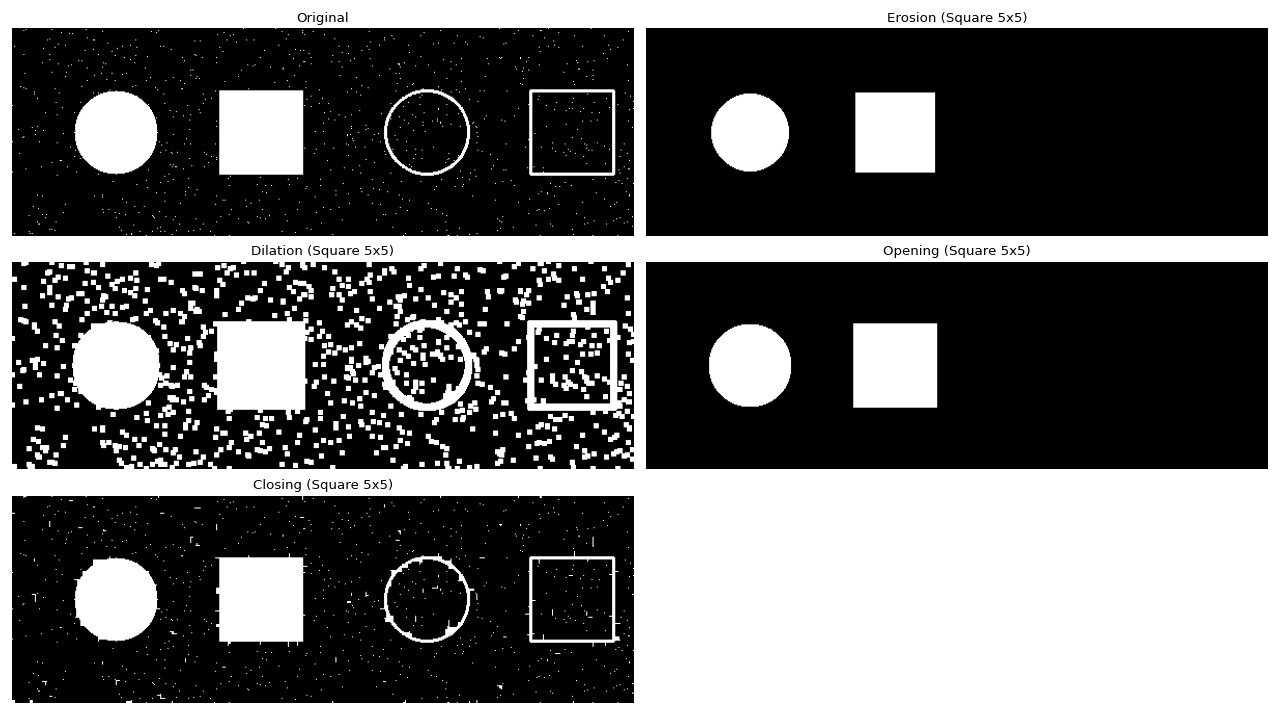

In [6]:
erosion_sq = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results_sq = [
    ('Original', image),
    ('Erosion (Square 5x5)', erosion_sq),
    ('Dilation (Square 5x5)', dilation_sq),
    ('Opening (Square 5x5)', opening_sq),
    ('Closing (Square 5x5)', closing_sq),
]

plt.figure(figsize=(16, 9))
for i, (title, img) in enumerate(results_sq, 1):
    plt.subplot(3, 2, i)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [7]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

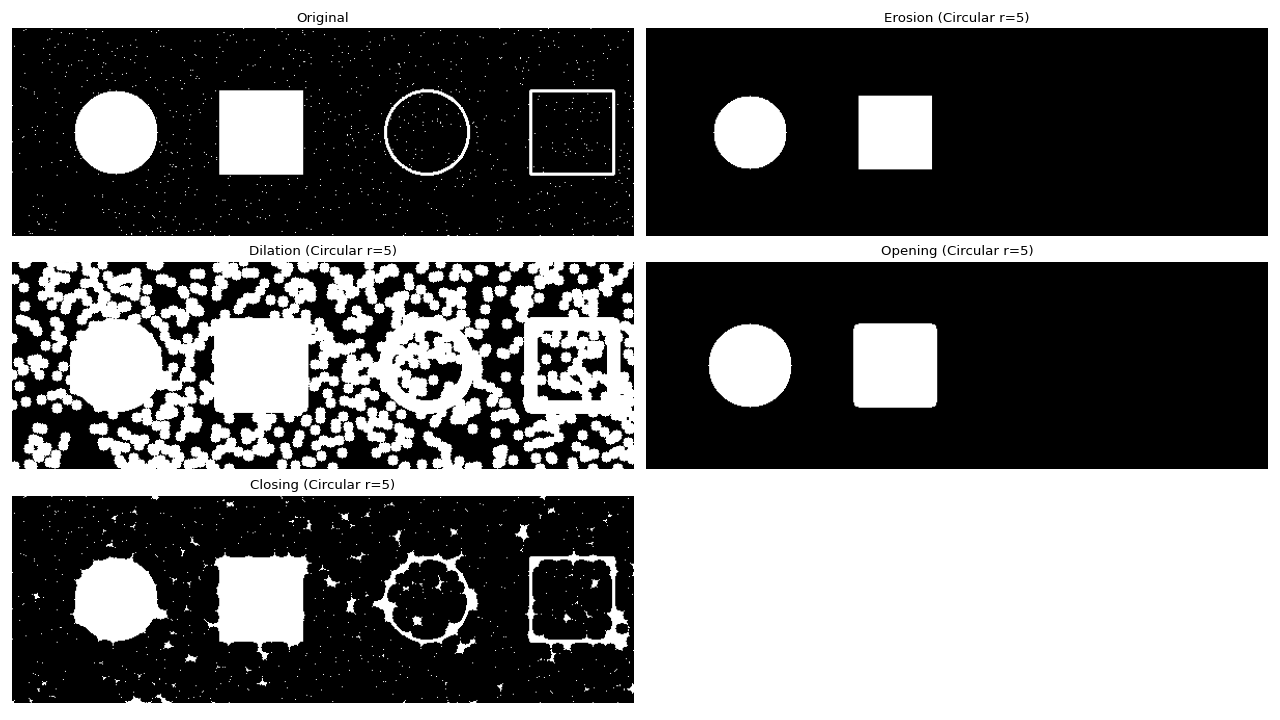

In [8]:
erosion_ci = cv2.erode(image, circle_kernel, iterations=1)
dilation_ci = cv2.dilate(image, circle_kernel, iterations=1)
opening_ci = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_ci = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_ci = [
    ('Original', image),
    ('Erosion (Circular r=5)', erosion_ci),
    ('Dilation (Circular r=5)', dilation_ci),
    ('Opening (Circular r=5)', opening_ci),
    ('Closing (Circular r=5)', closing_ci),
]

plt.figure(figsize=(16, 9))
for i, (title, img) in enumerate(results_ci, 1):
    plt.subplot(3, 2, i)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



**Answer:**

Both kernels follow the same basic rules: erosion shrinks, dilation grows, opening removes the salt noise while keeping the solid shapes, and closing fills gaps. The difference is in how strongly and in what shape each kernel acts. The circular kernel has radius 5, so it is 11×11, while the square kernel is 5×5. Part of the difference below comes from that larger size and part from the round shape.

| Operation | Square 5×5 (white pixels) | Circular r=5 (white pixels) |
|---|---|---|
| Original | 14165 | 14165 |
| Erosion | 10335 | 8903 |
| Dilation | 35685 | 67938 |
| Opening | 11583 | 11547 |
| Closing | 14707 | 17834 |

- **Erosion:** both remove all the noise and shrink the solid shapes. The circular kernel removes more (8903 vs 10335 pixels left), because it is larger. Both completely erase the two hollow shapes, since their outlines are only about 3 pixels thick and thinner than either kernel.
- **Dilation:** this shows the shape difference most clearly. With the square kernel each noise pixel becomes a small 5×5 square and the shapes keep their sharp corners. With the circular kernel each noise pixel becomes a round blob about 11 pixels across, and the shapes grow much more (67938 vs 35685 pixels). The result looks smoother and rounder, the hollow outlines thicken, and the noise blobs crowd in and merge with them.
- **Opening:** the noise is gone in both cases and the solid shapes keep almost their original size, so the totals are very close (11583 vs 11547). The square kernel keeps the rectangle corners sharp. The circular kernel slightly rounds them. Both erase the hollow shapes.
- **Closing:** both keep the solid shapes, and the hollow outlines survive but pick up extra pixels where nearby noise merges into them. The noise is not removed, it is only merged and enlarged. The circular kernel leaves more of it behind (17834 vs 14707 pixels) and the result is smoother and rounder.

**Summary:** the square kernel is gentler and preserves straight edges and corners, so it suits the rectangles. The circular kernel treats every direction equally, gives smoother and rounder results, and rounds off corners, but its larger footprint changes the image more. For removing the salt noise, opening works well with either kernel.